# 체크스윙 판정 시스템 - 모델 성능 평가
## Model Performance Evaluation

홈플레이트 감지 모델(homeplate.pt)과 배트 감지 모델(best.pt)의 성능을 종합 평가합니다.

In [1]:
import cv2
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt
import os

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
# ==========================================
# 모델 로드
# ==========================================
homeplate_model = YOLO('homeplate.pt')
bat_model = YOLO('best.pt')

print("✅ 모델 로드 완료")
print(f"   홈플레이트 모델: {homeplate_model.model}")
print(f"   배트 모델: {bat_model.model}")

✅ 모델 로드 완료
   홈플레이트 모델: PoseModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace

In [3]:
# ==========================================
# 테스트 영상 목록
# ==========================================
test_videos = [
    'checkswingtest2.mp4',
    'checkswingtest3.mp4',
    'checkswing2025.mp4'
]

# 존재하는 영상만 필터링
test_videos = [v for v in test_videos if os.path.exists(v)]
print(f"테스트 영상: {test_videos}")

테스트 영상: ['checkswingtest2.mp4', 'checkswingtest3.mp4', 'checkswing2025.mp4']


In [4]:
# ==========================================
# 모델 성능 평가 함수
# ==========================================

def evaluate_model_on_video(video_path, model, model_name, conf_threshold=0.3):
    """
    영상에서 모델 성능 평가
    """
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    detected_frames = 0
    confidences = []
    keypoints_per_frame = []
    
    frame_idx = 0
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        
        results = model(frame, conf=conf_threshold, verbose=False)
        
        if results[0].boxes is not None and len(results[0].boxes) > 0:
            detected_frames += 1
            conf = results[0].boxes.conf.max().item()
            confidences.append(conf)
            
            if results[0].keypoints is not None:
                kpts = results[0].keypoints[0].xy.cpu().numpy()[0]
                valid_kpts = sum(1 for x, y in kpts if x > 1 and y > 1)
                keypoints_per_frame.append(valid_kpts)
        
        frame_idx += 1
    
    cap.release()
    
    # 결과 계산
    detection_rate = detected_frames / total_frames * 100 if total_frames > 0 else 0
    avg_confidence = np.mean(confidences) if confidences else 0
    avg_keypoints = np.mean(keypoints_per_frame) if keypoints_per_frame else 0
    
    return {
        'video': video_path,
        'model': model_name,
        'total_frames': total_frames,
        'detected_frames': detected_frames,
        'detection_rate': detection_rate,
        'avg_confidence': avg_confidence,
        'avg_keypoints': avg_keypoints,
        'confidences': confidences
    }

In [5]:
# ==========================================
# 성능 평가 실행
# ==========================================

results_homeplate = []
results_bat = []

print("="*60)
print("모델 성능 평가 시작")
print("="*60)

for video in test_videos:
    print(f"\n📹 영상: {video}")
    
    # 홈플레이트 모델 평가
    print("   홈플레이트 모델 평가 중...")
    hp_result = evaluate_model_on_video(video, homeplate_model, 'Homeplate')
    results_homeplate.append(hp_result)
    print(f"   → 감지율: {hp_result['detection_rate']:.1f}%, 평균 신뢰도: {hp_result['avg_confidence']:.3f}")
    
    # 배트 모델 평가
    print("   배트 모델 평가 중...")
    bat_result = evaluate_model_on_video(video, bat_model, 'Bat')
    results_bat.append(bat_result)
    print(f"   → 감지율: {bat_result['detection_rate']:.1f}%, 평균 신뢰도: {bat_result['avg_confidence']:.3f}")

print("\n" + "="*60)
print("평가 완료!")
print("="*60)

모델 성능 평가 시작

📹 영상: checkswingtest2.mp4
   홈플레이트 모델 평가 중...
   → 감지율: 100.0%, 평균 신뢰도: 0.834
   배트 모델 평가 중...
   → 감지율: 70.0%, 평균 신뢰도: 0.735

📹 영상: checkswingtest3.mp4
   홈플레이트 모델 평가 중...
   → 감지율: 100.0%, 평균 신뢰도: 0.804
   배트 모델 평가 중...
   → 감지율: 85.7%, 평균 신뢰도: 0.685

📹 영상: checkswing2025.mp4
   홈플레이트 모델 평가 중...
   → 감지율: 100.0%, 평균 신뢰도: 0.749
   배트 모델 평가 중...
   → 감지율: 95.6%, 평균 신뢰도: 0.776

평가 완료!


In [6]:
# ==========================================
# 종합 결과 테이블
# ==========================================

print("\n" + "="*80)
print("📊 종합 성능 결과 (Performance Summary)")
print("="*80)

print("\n[홈플레이트 감지 모델 (Homeplate Detection Model)]")
print("-"*80)
print(f"{'영상':<25} {'총 프레임':>10} {'감지 프레임':>12} {'감지율':>10} {'평균 신뢰도':>12}")
print("-"*80)

total_hp_frames = 0
total_hp_detected = 0
all_hp_conf = []

for r in results_homeplate:
    print(f"{r['video']:<25} {r['total_frames']:>10} {r['detected_frames']:>12} {r['detection_rate']:>9.1f}% {r['avg_confidence']:>11.3f}")
    total_hp_frames += r['total_frames']
    total_hp_detected += r['detected_frames']
    all_hp_conf.extend(r['confidences'])

print("-"*80)
hp_total_rate = total_hp_detected / total_hp_frames * 100 if total_hp_frames > 0 else 0
hp_avg_conf = np.mean(all_hp_conf) if all_hp_conf else 0
print(f"{'[종합]':<25} {total_hp_frames:>10} {total_hp_detected:>12} {hp_total_rate:>9.1f}% {hp_avg_conf:>11.3f}")

print("\n[배트 감지 모델 (Bat Detection Model)]")
print("-"*80)
print(f"{'영상':<25} {'총 프레임':>10} {'감지 프레임':>12} {'감지율':>10} {'평균 신뢰도':>12}")
print("-"*80)

total_bat_frames = 0
total_bat_detected = 0
all_bat_conf = []

for r in results_bat:
    print(f"{r['video']:<25} {r['total_frames']:>10} {r['detected_frames']:>12} {r['detection_rate']:>9.1f}% {r['avg_confidence']:>11.3f}")
    total_bat_frames += r['total_frames']
    total_bat_detected += r['detected_frames']
    all_bat_conf.extend(r['confidences'])

print("-"*80)
bat_total_rate = total_bat_detected / total_bat_frames * 100 if total_bat_frames > 0 else 0
bat_avg_conf = np.mean(all_bat_conf) if all_bat_conf else 0
print(f"{'[종합]':<25} {total_bat_frames:>10} {total_bat_detected:>12} {bat_total_rate:>9.1f}% {bat_avg_conf:>11.3f}")


📊 종합 성능 결과 (Performance Summary)

[홈플레이트 감지 모델 (Homeplate Detection Model)]
--------------------------------------------------------------------------------
영상                             총 프레임       감지 프레임        감지율       평균 신뢰도
--------------------------------------------------------------------------------
checkswingtest2.mp4               70           70     100.0%       0.834
checkswingtest3.mp4              224          224     100.0%       0.804
checkswing2025.mp4               137          137     100.0%       0.749
--------------------------------------------------------------------------------
[종합]                             431          431     100.0%       0.791

[배트 감지 모델 (Bat Detection Model)]
--------------------------------------------------------------------------------
영상                             총 프레임       감지 프레임        감지율       평균 신뢰도
--------------------------------------------------------------------------------
checkswingtest2.mp4               70        

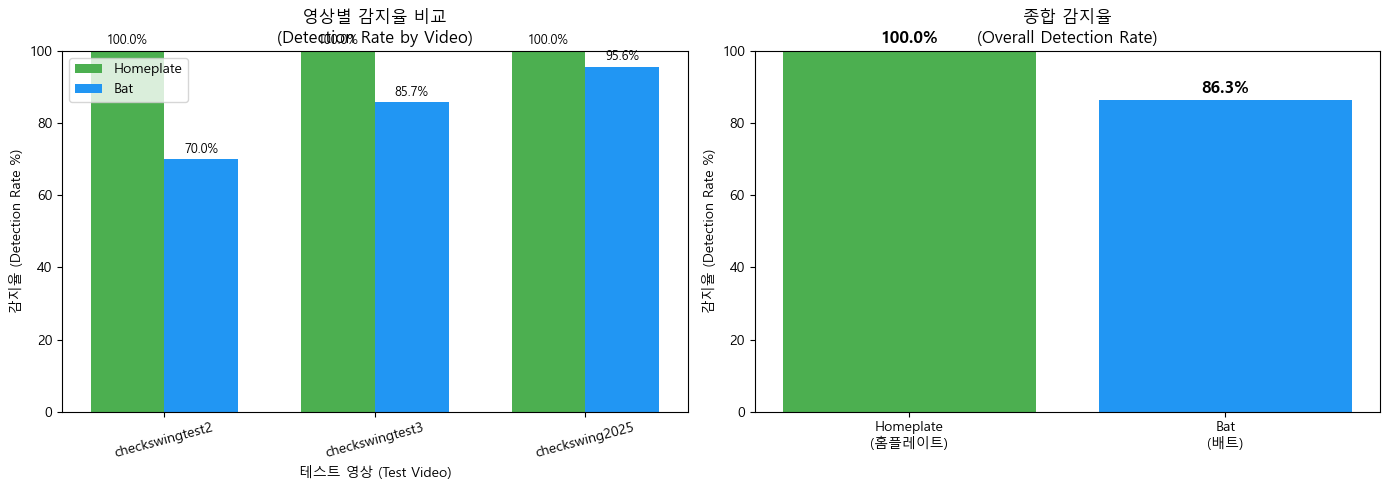

📊 저장됨: model_detection_rate.png


In [7]:
# ==========================================
# 그래프 1: 감지율 비교
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 영상별 감지율
video_names = [r['video'].replace('.mp4', '') for r in results_homeplate]
hp_rates = [r['detection_rate'] for r in results_homeplate]
bat_rates = [r['detection_rate'] for r in results_bat]

x = np.arange(len(video_names))
width = 0.35

bars1 = axes[0].bar(x - width/2, hp_rates, width, label='Homeplate', color='#4CAF50')
bars2 = axes[0].bar(x + width/2, bat_rates, width, label='Bat', color='#2196F3')

axes[0].set_xlabel('테스트 영상 (Test Video)')
axes[0].set_ylabel('감지율 (Detection Rate %)')
axes[0].set_title('영상별 감지율 비교\n(Detection Rate by Video)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(video_names, rotation=15)
axes[0].legend()
axes[0].set_ylim(0, 100)

# 값 표시
for bar, rate in zip(bars1, hp_rates):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate:.1f}%', 
                 ha='center', va='bottom', fontsize=9)
for bar, rate in zip(bars2, bat_rates):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate:.1f}%', 
                 ha='center', va='bottom', fontsize=9)

# 종합 감지율
models = ['Homeplate\n(홈플레이트)', 'Bat\n(배트)']
total_rates = [hp_total_rate, bat_total_rate]
colors = ['#4CAF50', '#2196F3']

bars = axes[1].bar(models, total_rates, color=colors)
axes[1].set_ylabel('감지율 (Detection Rate %)')
axes[1].set_title('종합 감지율\n(Overall Detection Rate)')
axes[1].set_ylim(0, 100)

for bar, rate in zip(bars, total_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate:.1f}%', 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('model_detection_rate.png', dpi=150, bbox_inches='tight')
plt.show()
print("📊 저장됨: model_detection_rate.png")

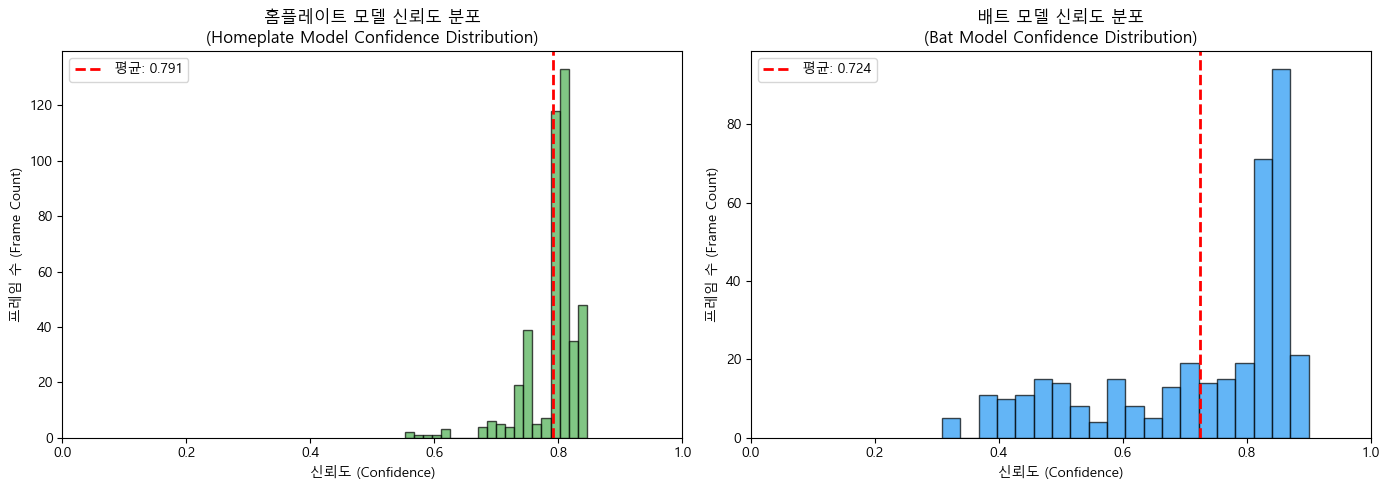

📊 저장됨: model_confidence_distribution.png


In [8]:
# ==========================================
# 그래프 2: 신뢰도 분포
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 홈플레이트 신뢰도 분포
axes[0].hist(all_hp_conf, bins=20, color='#4CAF50', alpha=0.7, edgecolor='black')
axes[0].axvline(hp_avg_conf, color='red', linestyle='--', linewidth=2, label=f'평균: {hp_avg_conf:.3f}')
axes[0].set_xlabel('신뢰도 (Confidence)')
axes[0].set_ylabel('프레임 수 (Frame Count)')
axes[0].set_title('홈플레이트 모델 신뢰도 분포\n(Homeplate Model Confidence Distribution)')
axes[0].legend()
axes[0].set_xlim(0, 1)

# 배트 신뢰도 분포
axes[1].hist(all_bat_conf, bins=20, color='#2196F3', alpha=0.7, edgecolor='black')
axes[1].axvline(bat_avg_conf, color='red', linestyle='--', linewidth=2, label=f'평균: {bat_avg_conf:.3f}')
axes[1].set_xlabel('신뢰도 (Confidence)')
axes[1].set_ylabel('프레임 수 (Frame Count)')
axes[1].set_title('배트 모델 신뢰도 분포\n(Bat Model Confidence Distribution)')
axes[1].legend()
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig('model_confidence_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("📊 저장됨: model_confidence_distribution.png")

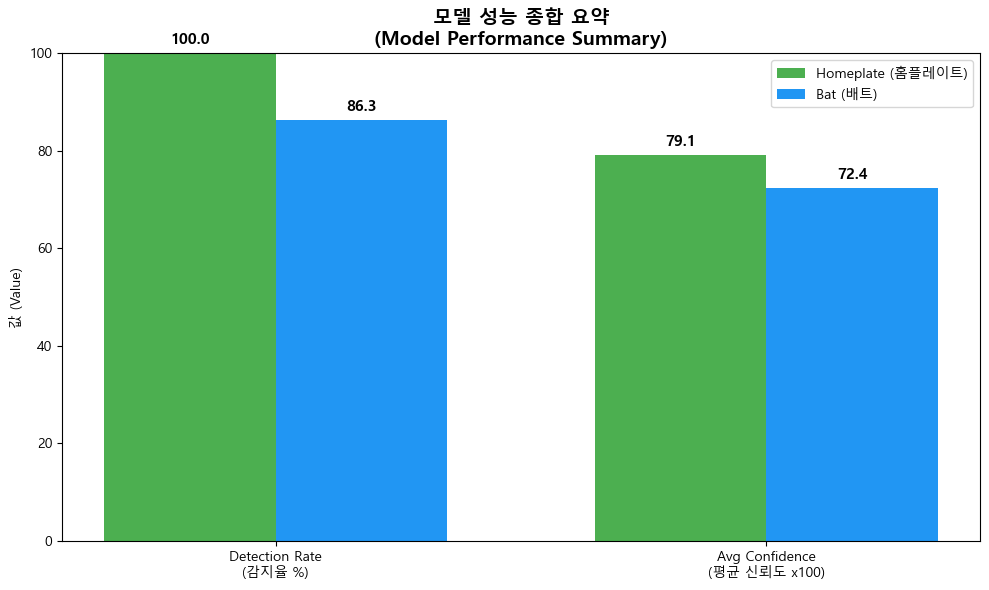

📊 저장됨: model_performance_summary.png


In [9]:
# ==========================================
# 그래프 3: 종합 성능 요약
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

# 데이터
metrics = ['Detection Rate\n(감지율 %)', 'Avg Confidence\n(평균 신뢰도 x100)']
hp_values = [hp_total_rate, hp_avg_conf * 100]
bat_values = [bat_total_rate, bat_avg_conf * 100]

x = np.arange(len(metrics))
width = 0.35

bars1 = ax.bar(x - width/2, hp_values, width, label='Homeplate (홈플레이트)', color='#4CAF50')
bars2 = ax.bar(x + width/2, bat_values, width, label='Bat (배트)', color='#2196F3')

ax.set_ylabel('값 (Value)')
ax.set_title('모델 성능 종합 요약\n(Model Performance Summary)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim(0, 100)

# 값 표시
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1, f'{height:.1f}', 
            ha='center', va='bottom', fontsize=11, fontweight='bold')
for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 1, f'{height:.1f}', 
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('model_performance_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("📊 저장됨: model_performance_summary.png")

In [10]:
# ==========================================
# 최종 성능 요약 출력 (논문용)
# ==========================================

print("\n" + "="*70)
print("📝 논문용 성능 요약 (Performance Summary for Paper)")
print("="*70)

print(f"""
┌────────────────────────────────────────────────────────────────────┐
│                    Model Performance Results                       │
├────────────────────────────────────────────────────────────────────┤
│  Model              │ Detection Rate │ Avg Confidence │ Test Frames│
├────────────────────────────────────────────────────────────────────┤
│  Homeplate (홈플레이트) │     {hp_total_rate:>6.2f}%    │      {hp_avg_conf:.4f}     │    {total_hp_frames:>5}    │
│  Bat (배트)            │     {bat_total_rate:>6.2f}%    │      {bat_avg_conf:.4f}     │    {total_bat_frames:>5}    │
└────────────────────────────────────────────────────────────────────┘

Test Videos: {len(test_videos)} videos
Total Frames Analyzed: {total_hp_frames}

Generated Graphs:
  1. model_detection_rate.png - 감지율 비교 그래프
  2. model_confidence_distribution.png - 신뢰도 분포 그래프  
  3. model_performance_summary.png - 종합 성능 요약 그래프
""")


📝 논문용 성능 요약 (Performance Summary for Paper)

┌────────────────────────────────────────────────────────────────────┐
│                    Model Performance Results                       │
├────────────────────────────────────────────────────────────────────┤
│  Model              │ Detection Rate │ Avg Confidence │ Test Frames│
├────────────────────────────────────────────────────────────────────┤
│  Homeplate (홈플레이트) │     100.00%    │      0.7913     │      431    │
│  Bat (배트)            │      86.31%    │      0.7237     │      431    │
└────────────────────────────────────────────────────────────────────┘

Test Videos: 3 videos
Total Frames Analyzed: 431

Generated Graphs:
  1. model_detection_rate.png - 감지율 비교 그래프
  2. model_confidence_distribution.png - 신뢰도 분포 그래프  
  3. model_performance_summary.png - 종합 성능 요약 그래프

